# Olist: Calidad de datos

# Proyecto 1 — Limpieza de datos con Python y (DuckDB/SQLite)
### Introducción al Análisis de Datos (MIICC409)

---

| Carné | Nombre completo |
|---|---|
| 999020963 | Manuel Alexander Ajanel Jerónimo |

## 1. Introducción

Una empresa de comercio electrónico necesita mejorar la calidad de sus datos transaccionales. En el proyecto se diseña un pipeline ETL para identificar, corregir, documentar y validar problemas de calidad utilizando SQL en DuckDB y Python para la orquestación

Práctica reproducible: **originales → copias alteradas → RAW → diagnóstico SQL → CLEAN →
auditoría → controles → idempotencia → Parquet**. Ejecutar todas las celdas en orden.

Se utilizan exclusivamente customers, orders, order_items, order_payments y products.
`customer_unique_id` identifica una persona a través de compras, pero **no es una clave única**.
Las claves son `customer_id`, `order_id`, `product_id`, `(order_id, order_item_id)` y
`(order_id, payment_sequential)`. `seller_id` se conserva como atributo de origen:
no se consulta ni se valida contra un sexto dataset.


## 2. Herramientas y configuración
Python 3.10+ y un kernel Python estándar. Sólo se instalan paquetes ausentes usando
`sys.executable`; no se activa ni se requiere un entorno con nombre específico.
Configure las dos rutas siguientes. En Colab coloque los archivos en `data/raw`;
en Kaggle puede apuntar `INPUT_DIR` a la carpeta adjunta y `OUTPUT_DIR` a una carpeta escribible.
Las versiones realmente usadas se registran en la auditoría. DuckDB escribe Parquet sin PyArrow.


In [1]:
import sys, subprocess, importlib.util, importlib.metadata

for package in ("duckdb", "pandas", "matplotlib"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])
import csv, hashlib, json, random, shutil, tempfile, os
from pathlib import Path
from datetime import datetime, timezone
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

INPUT_DIR = Path("data/raw")
OUTPUT_DIR = Path("resultados_simplificado")
DOWNLOAD_FROM_KAGGLE = False  # Cambiar a True sólo para descargar archivos faltantes.
SEED = 42
POLICY_VERSION = "five-tables-v1.0"
TOLERANCE = "0.01"  # Importe decimal, nunca float para conciliación.
VERSIONS = {
    p: importlib.metadata.version(p) for p in ("duckdb", "pandas", "matplotlib")
}
VERSIONS["python"] = sys.version.split()[0]
if "con" in globals():
    con.close()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if INPUT_DIR.resolve() == OUTPUT_DIR.resolve() or INPUT_DIR.resolve().is_relative_to(
    OUTPUT_DIR.resolve()
):
    raise ValueError("La entrada debe estar separada del árbol de resultados.")
DB_PATH = OUTPUT_DIR / "olist_data_quality.duckdb"
COPIES_DIR = OUTPUT_DIR / "copias_con_errores"
print("Versiones:", VERSIONS)
print("Entrada:", INPUT_DIR, "| Resultados:", OUTPUT_DIR)


Versiones: {'duckdb': '2.0.0', 'pandas': '2.3.3', 'matplotlib': '3.11.2', 'python': '3.12.16'}
Entrada: data\raw | Resultados: resultados_simplificado


In [2]:
# Contrato explícito de los cinco CSV. Se conserva la ortografía original "lenght".
SCHEMA = {
    "customers": "customer_id customer_unique_id customer_zip_code_prefix customer_city customer_state".split(),
    "orders": "order_id customer_id order_status order_purchase_timestamp order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date".split(),
    "order_items": "order_id order_item_id product_id seller_id shipping_limit_date price freight_value".split(),
    "order_payments": "order_id payment_sequential payment_type payment_installments payment_value".split(),
    "products": "product_id product_category_name product_name_lenght product_description_lenght product_photos_qty product_weight_g product_length_cm product_height_cm product_width_cm".split(),
}
FILES = {t: f"olist_{t}_dataset.csv" for t in SCHEMA}
KEYS = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "products": ["product_id"],
    "order_items": ["order_id", "order_item_id"],
    "order_payments": ["order_id", "payment_sequential"],
}
REQUIRED = {
    "customers": ["customer_id", "customer_unique_id"],
    "orders": [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
    ],
    "order_items": [
        "order_id",
        "order_item_id",
        "product_id",
        "seller_id",
        "price",
        "freight_value",
    ],
    "order_payments": [
        "order_id",
        "payment_sequential",
        "payment_type",
        "payment_value",
    ],
    "products": ["product_id"],
}
RELATIONS = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_payments", "order_id", "orders", "order_id"),
]
MONEY = {"order_items": ["price", "freight_value"], "order_payments": ["payment_value"]}
TYPES = {t: {c: "VARCHAR" for c in cols} for t, cols in SCHEMA.items()}
for c in SCHEMA["orders"][3:]:
    TYPES["orders"][c] = "TIMESTAMP"
TYPES["order_items"].update(order_item_id="INTEGER", shipping_limit_date="TIMESTAMP")
TYPES["order_payments"].update(
    payment_sequential="INTEGER", payment_installments="INTEGER"
)
for t, cols in MONEY.items():
    for c in cols:
        TYPES[t][c] = "DECIMAL(18,2)"
for c in SCHEMA["products"][2:]:
    TYPES["products"][c] = "DOUBLE" if c in SCHEMA["products"][5:] else "INTEGER"
STATUSES = "('created','approved','invoiced','processing','shipped','delivered','unavailable','canceled')"
METHODS = "('credit_card','boleto','voucher','debit_card','not_defined')"
RULE_NAMES = dict(
    zip(
        [f"R{i:02}" for i in range(1, 16)],
        [
            "Duplicados",
            "Nulos",
            "Texto",
            "Tipos",
            "Fechas",
            "Importes",
            "Atípicos IQR",
            "Categorías",
            "Integridad referencial",
            "Estados",
            "Postales",
            "Conciliación",
            "Métodos de pago",
            "Cadenas vacías",
            "Control final",
        ],
    )
)


def qi(s):
    return '"' + s.replace('"', '""') + '"'


def qs(s):
    return "'" + str(s).replace("'", "''") + "'"


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def scalar(sql):
    return con.execute(sql).fetchall()[0][0]


def signature(relation):
    return [
        (r[0], r[1])
        for r in con.execute(f"DESCRIBE SELECT * FROM {relation}").fetchall()
    ]


def differences(a, b):
    return scalar(
        f"SELECT count(*) FROM ((SELECT * FROM {a} EXCEPT ALL SELECT * FROM {b}) "
        f"UNION ALL (SELECT * FROM {b} EXCEPT ALL SELECT * FROM {a}))"
    )


## 3. Obtención de datos
Modo A usa únicamente los cinco nombres permitidos, aunque la carpeta contenga otros archivos.
Modo B descarga cada archivo faltante por separado desde
[Kaggle/Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), usando
[`kagglehub.dataset_download(path=...)`](https://github.com/Kaggle/kagglehub).
La creación exclusiva `xb` impide sobrescribir un CSV existente, incluso ante una carrera.
Si la descarga falla, el mensaje indica cómo completar la entrada manualmente.


In [3]:
missing = [name for name in FILES.values() if not (INPUT_DIR / name).is_file()]
if missing and DOWNLOAD_FROM_KAGGLE:
    try:
        if importlib.util.find_spec("kagglehub") is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "kagglehub"])
        import kagglehub

        INPUT_DIR.mkdir(parents=True, exist_ok=True)
        for name in missing:
            downloaded = Path(
                kagglehub.dataset_download("olistbr/brazilian-ecommerce", path=name)
            )
            source = downloaded / name if downloaded.is_dir() else downloaded
            # Leer antes de crear el destino evita dejar archivos parciales por fallo de red.
            payload = source.read_bytes()
            with (INPUT_DIR / name).open("xb") as f:
                f.write(payload)
    except Exception as exc:
        raise RuntimeError(
            f"Descarga incompleta: {exc}. Coloque manualmente los cinco CSV en {INPUT_DIR}."
        ) from exc
missing = [name for name in FILES.values() if not (INPUT_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"Faltan {missing}. Colóquelos en {INPUT_DIR} o active DOWNLOAD_FROM_KAGGLE."
    )


## 4. Exploración inicial
Se cuentan registros CSV, no líneas físicas. Se validan cabeceras y anchura de cada registro,
y se registra tamaño, SHA-256, nulos representados por campos vacíos y duplicados exactos.
Un CSV no distingue por sí mismo un NULL de una cadena vacía: RAW conserva ambos como texto;
R14 interpreta el campo vacío como ausente. No se modifica ningún archivo original.


In [4]:
def inventory():
    result = []
    for t, name in FILES.items():
        path = INPUT_DIR / name
        with path.open(encoding="utf-8-sig", newline="") as f:
            reader = csv.reader(f)
            cols = next(reader)
            if cols != SCHEMA[t]:
                raise ValueError(f"Esquema inesperado: {name}: {cols}")
            n, blanks, seen, duplicates = 0, 0, set(), 0
            for row in reader:
                if len(row) != len(cols):
                    raise ValueError(f"{name}, registro {n + 1}: anchura incorrecta")
                n += 1
                blanks += sum(not v.strip() for v in row)
                key = tuple(row)
                duplicates += key in seen
                seen.add(key)
        result.append(
            dict(
                tabla=t,
                archivo=name,
                registros=n,
                bytes=path.stat().st_size,
                sha256=sha256(path),
                columnas=cols,
                campos_vacios=blanks,
                duplicados_exactos=duplicates,
            )
        )
    return result


ORIGINALS = inventory()
CONFIG = {
    "policy": POLICY_VERSION,
    "seed": SEED,
    "tolerance": TOLERANCE,
    "versions": VERSIONS,
    "inputs": {r["archivo"]: r["sha256"] for r in ORIGINALS},
}
RUN_ID = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()
display(pd.DataFrame(ORIGINALS))
display(
    pd.DataFrame(
        [(t, ", ".join(KEYS[t]), len(SCHEMA[t])) for t in SCHEMA],
        columns=["tabla", "clave", "columnas"],
    )
)
print("Ejecución lógica:", RUN_ID)


,tabla,archivo,registros,bytes,sha256,columnas,campos_vacios,duplicados_exactos
0,customers,olist_customers_dataset.csv,99441,9033957,983a422239e1712ded753b3bf9ecf47dc73f144d306029...,"[customer_id, customer_unique_id, customer_zip...",0,0
1,orders,olist_orders_dataset.csv,99441,17654914,8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c9...,"[order_id, customer_id, order_status, order_pu...",4908,0
2,order_items,olist_order_items_dataset.csv,112650,15438671,0bc4d068c4fe38cbb01bd90e8746e3c613fe7b4baef75f...,"[order_id, order_item_id, product_id, seller_i...",0,0
3,order_payments,olist_order_payments_dataset.csv,103886,5777138,4f713964f2815dbbaa40b9488268c55aac3627bfce5aa9...,"[order_id, payment_sequential, payment_type, p...",0,0
4,products,olist_products_dataset.csv,32951,2379446,3e6569628a17fbc75fd206ee357b59e20364b9afa90f5b...,"[product_id, product_category_name, product_na...",2448,0


,tabla,clave,columnas
0,customers,customer_id,5
1,orders,order_id,8
2,order_items,"order_id, order_item_id",7
3,order_payments,"order_id, payment_sequential",5
4,products,product_id,9


Ejecución lógica: 9a1da5be5a37e03e8633d9000df74649425d2666824ccb8292eb8c42c3f5d2cd


## 5. Generación de errores controlados
Cada copia se reconstruye desde el original con semilla 42, sin acumular corrupciones.
Se eligen filas distintas por tabla. Los conflictos de clave afectan a **ambas versiones**,
que se retienen en cuarentena; una copia exacta permite conservar una sola representación.
Los identificadores no se reparan utilizando la fuente original.

El catálogo contiene fila (base 1, sin cabecera), clave, campo, antes/después, regla esperada
y efectos secundarios previstos. Las bajas de padres pueden causar cuarentenas de hijos;
las bajas de artículos/pagos pueden generar discrepancias (regla de limpieza 12). El diagnóstico antes de
limpiar se ejecuta sobre todo RAW, por lo que esas dependencias no ocultan las inyecciones.


In [5]:
def generate_copies():
    COPIES_DIR.mkdir(parents=True, exist_ok=True)
    rng, catalog = random.Random(SEED), []
    for t, name in FILES.items():
        with (INPUT_DIR / name).open(encoding="utf-8-sig", newline="") as f:
            rows = list(csv.DictReader(f))
        candidates = list(range(len(rows)))
        rng.shuffle(candidates)
        used = set()

        def pick(field=None, temporal=False):
            for i in candidates:
                r = rows[i]
                if i in used or (field and not r[field].strip()):
                    continue
                if temporal and not (
                    r["order_status"] == "delivered"
                    and all(r[c] for c in SCHEMA["orders"][3:])
                    and r["order_purchase_timestamp"]
                    <= r["order_delivered_carrier_date"]
                    <= r["order_delivered_customer_date"]
                ):
                    continue
                used.add(i)
                return i
            raise ValueError(
                f"{t}: datos insuficientes para demostrar las inyecciones."
            )

        def record(
            i,
            field,
            before,
            after,
            rule,
            kind,
            effects="Puede solaparse con otras reglas; véase audit.findings.",
        ):
            catalog.append(
                dict(
                    injection_id=f"I{len(catalog) + 1:03}",
                    tabla=t,
                    archivo=name,
                    fila=i + 1,
                    clave=json.dumps({k: rows[i][k] for k in KEYS[t]}, sort_keys=True),
                    campo=field,
                    valor_anterior=before,
                    valor_inyectado=after,
                    tipo_error=kind,
                    regla_esperada=rule,
                    efectos=effects,
                )
            )

        def change(field, value, rule, kind, temporal=False):
            i = pick(field, temporal)
            before = rows[i][field]
            after = value(before, rows[i]) if callable(value) else value
            rows[i][field] = after
            record(i, field, before, after, rule, kind)

        i = pick()
        rows.append(rows[i].copy())
        record(
            len(rows) - 1,
            "*",
            json.dumps(rows[i], sort_keys=True),
            json.dumps(rows[i], sort_keys=True),
            "R01",
            "duplicado exacto",
        )
        conflict_field = {
            "customers": "customer_city",
            "orders": "order_status",
            "products": "product_category_name",
            "order_items": "price",
            "order_payments": "payment_value",
        }[t]
        i = pick(conflict_field)
        duplicate = rows[i].copy()
        duplicate[conflict_field] = "123.45" if t in MONEY else "conflicto_controlado"
        if duplicate == rows[i]:
            duplicate[conflict_field] = "543.21"
        rows.append(duplicate)
        record(
            len(rows) - 1,
            conflict_field,
            rows[i][conflict_field],
            duplicate[conflict_field],
            "R01",
            "clave conflictiva",
            "Ambas versiones quedan en cuarentena; puede propagar R09/R12 y R10 en orders.",
        )
        if t == "customers":
            change("customer_unique_id", "", "R02", "nulo obligatorio")
            change("customer_city", "   ", "R14", "sólo espacios opcional")
            change(
                "customer_state",
                lambda v, r: "  " + v.lower() + "  ",
                "R03",
                "texto no canónico",
            )
            change(
                "customer_zip_code_prefix", "123", "R11", "prefijo corto recuperable"
            )
            change("customer_zip_code_prefix", "12X-9", "R11", "prefijo no recuperable")
        elif t == "orders":
            change("order_approved_at", "fecha-invalida", "R04", "fecha inválida", True)
            change(
                "order_delivered_carrier_date",
                "2000-01-01 00:00:00",
                "R05",
                "transportista antes de compra",
                True,
            )
            change(
                "order_delivered_customer_date",
                "2000-01-01 00:00:00",
                "R05",
                "entrega antes de compra",
                True,
            )
            change(
                "customer_id",
                "cliente_inexistente_controlado",
                "R09",
                "cliente huérfano",
                True,
            )
            change(
                "order_status", "estado_desconocido", "R10", "estado desconocido", True
            )
            change(
                "order_delivered_customer_date",
                "",
                "R10",
                "delivered sin entrega",
                True,
            )
            change(
                "order_status",
                lambda v, r: "  " + v.upper() + " ",
                "R03",
                "estado con formato inconsistente",
                True,
            )
        elif t == "order_items":
            change("order_item_id", "1.5", "R04", "entero fraccionario")
            change("price", "-9.99", "R06", "precio negativo")
            change("freight_value", "importe-invalido", "R06", "flete no convertible")
            change("price", "10.005", "R06", "centavos no representables sin redondeo")
            change("price", "99999999.00", "R07", "extremo positivo; también R12")
            change(
                "order_id", "pedido_inexistente_controlado", "R09", "pedido huérfano"
            )
            change(
                "product_id",
                "producto_inexistente_controlado",
                "R09",
                "producto huérfano",
            )
        elif t == "order_payments":
            change("payment_value", "-1.00", "R06", "pago negativo")
            change(
                "payment_value",
                "9876543.21",
                "R12",
                "diferencia deliberada contra artículos; también IQR",
            )
            change("payment_value", "", "R02", "importe obligatorio ausente")
            change("payment_type", "metodo_desconocido", "R13", "método desconocido")
            change(
                "payment_type",
                lambda v, r: "  " + v.upper() + "  ",
                "R13",
                "método con formato equivalente",
            )
            change("payment_installments", "no-entero", "R04", "tipo inválido")
            change("payment_installments", "", "R02", "nulo opcional")
            change(
                "order_id", "pedido_pago_inexistente", "R09", "pedido de pago huérfano"
            )
        elif t == "products":
            change(
                "product_category_name",
                lambda v, r: "  " + v.upper() + "  ",
                "R08",
                "categoría con formato inconsistente",
            )
            change("product_category_name", "", "R02", "categoría opcional ausente")
            change("product_weight_g", "no-numero", "R04", "medida no convertible")
            change("product_photos_qty", "-2", "R04", "cantidad fuera de dominio")
        path = COPIES_DIR / name
        with path.open("w", encoding="utf-8", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=SCHEMA[t], lineterminator="\n")
            writer.writeheader()
            writer.writerows(rows)
    (OUTPUT_DIR / "inyecciones.json").write_text(
        json.dumps(catalog, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    return catalog


INJECTIONS = generate_copies()
display(pd.DataFrame(INJECTIONS))


,injection_id,tabla,archivo,fila,clave,campo,valor_anterior,valor_inyectado,tipo_error,regla_esperada,efectos
0,I001,customers,olist_customers_dataset.csv,99442,"{""customer_id"": ""f2bf47b246beb9ade08ed9fa3775e...",*,"{""customer_city"": ""perdigao"", ""customer_id"": ""...","{""customer_city"": ""perdigao"", ""customer_id"": ""...",duplicado exacto,R01,Puede solaparse con otras reglas; véase audit....
1,I002,customers,olist_customers_dataset.csv,99443,"{""customer_id"": ""b834ebad1af8421ec606cd94cd8ec...",customer_city,itu,conflicto_controlado,clave conflictiva,R01,Ambas versiones quedan en cuarentena; puede pr...
2,I003,customers,olist_customers_dataset.csv,56904,"{""customer_id"": ""6b3a20b24d577f4c35d290c9933e9...",customer_unique_id,3fde7f0e201f955c897b57d00e5f20dc,,nulo obligatorio,R02,Puede solaparse con otras reglas; véase audit....
3,I004,customers,olist_customers_dataset.csv,59467,"{""customer_id"": ""173b02d5ca1c65154f368ac76ecba...",customer_city,bauru,,sólo espacios opcional,R14,Puede solaparse con otras reglas; véase audit....
4,I005,customers,olist_customers_dataset.csv,6797,"{""customer_id"": ""402f75205b75b521681f67add1bf1...",customer_state,SP,sp,texto no canónico,R03,Puede solaparse con otras reglas; véase audit....
5,I006,customers,olist_customers_dataset.csv,55263,"{""customer_id"": ""48f393741354adda8d6fb24150557...",customer_zip_code_prefix,19065,123,prefijo corto recuperable,R11,Puede solaparse con otras reglas; véase audit....
6,I007,customers,olist_customers_dataset.csv,30518,"{""customer_id"": ""a48ffc7cf9fca7c48a49af83e7261...",customer_zip_code_prefix,04468,12X-9,prefijo no recuperable,R11,Puede solaparse con otras reglas; véase audit....
7,I008,orders,olist_orders_dataset.csv,99442,"{""order_id"": ""4e8b695203ce1447833493b8898ad943""}",*,"{""customer_id"": ""11a2098ba613a6da385f0160b1671...","{""customer_id"": ""11a2098ba613a6da385f0160b1671...",duplicado exacto,R01,Puede solaparse con otras reglas; véase audit....
8,I009,orders,olist_orders_dataset.csv,99443,"{""order_id"": ""bb0d79335145208b9dc833ad7edb99fd""}",order_status,delivered,conflicto_controlado,clave conflictiva,R01,Ambas versiones quedan en cuarentena; puede pr...
9,I010,orders,olist_orders_dataset.csv,24775,"{""order_id"": ""6c8301b08c7426b14823e6362151d190""}",order_approved_at,2018-05-10 16:58:49,fecha-invalida,fecha inválida,R04,Puede solaparse con otras reglas; véase audit....


## 6. Construcción de RAW
RAW guarda exactamente las columnas de entrada como VARCHAR, incluidos ceros iniciales,
espacios y cadenas vacías. Se desactiva la lectura paralela para mantener el número de fila
del catálogo. Las tablas temporales incorporan `_rid` para relacionar cada resultado con RAW.
Sólo RAW, CLEAN y AUDIT son persistentes.


In [6]:
con = duckdb.connect(str(DB_PATH))
con.execute("SET threads=2")
con.execute("SET preserve_insertion_order=true")
for schema in ("raw", "clean", "audit"):
    con.execute(f"CREATE SCHEMA IF NOT EXISTS {schema}")
con.execute("""CREATE TABLE IF NOT EXISTS audit.runs (
    run_id VARCHAR PRIMARY KEY, fecha_ejecucion TIMESTAMP, config_json VARCHAR)""")
prior = con.execute(
    "SELECT fecha_ejecucion FROM audit.runs WHERE run_id=?", [RUN_ID]
).fetchone()
RUN_TIME = prior[0] if prior else datetime.now(timezone.utc).replace(tzinfo=None)

AUDIT_DDL = {
    "sources": "tabla VARCHAR, archivo VARCHAR, registros BIGINT, bytes BIGINT, sha256 VARCHAR, columnas VARCHAR",
    "injections": "injection_id VARCHAR, tabla VARCHAR, archivo VARCHAR, fila BIGINT, clave VARCHAR, campo VARCHAR, valor_anterior VARCHAR, valor_inyectado VARCHAR, tipo_error VARCHAR, regla_esperada VARCHAR, efectos VARCHAR",
    "findings": "fase VARCHAR, regla VARCHAR, tabla VARCHAR, fila BIGINT, detalle VARCHAR, severidad VARCHAR, origen VARCHAR",
    "queries": "fase VARCHAR, regla VARCHAR, tabla VARCHAR, detalle VARCHAR, sql VARCHAR, severidad VARCHAR",
    "quarantine": "tabla VARCHAR, fila BIGINT, motivos VARCHAR, fila_original VARCHAR",
    "lineage": "tabla VARCHAR, fila BIGINT, clave VARCHAR",
    "changes": "regla VARCHAR, tabla VARCHAR, fila BIGINT, campo VARCHAR, antes VARCHAR, despues VARCHAR",
    "temporal_events": "fila BIGINT, order_id VARCHAR, motivo VARCHAR, timestamp_original TIMESTAMP, origen VARCHAR, politica VARCHAR",
    "rule_results": "regla VARCHAR, tabla VARCHAR, evaluados BIGINT, detectados BIGINT, corregidos BIGINT, cuarentena BIGINT, pendientes BIGINT, posteriores BIGINT",
    "injection_coverage": "injection_id VARCHAR, regla VARCHAR, detectada BOOLEAN",
    "checks": "control VARCHAR, evaluados BIGINT, invalidos BIGINT, estado VARCHAR, sql VARCHAR",
    "negative_tests": "prueba VARCHAR, control_esperado VARCHAR, detectado BOOLEAN",
    "quality_report": """nombre_regla VARCHAR, tabla_evaluada VARCHAR, registros_evaluados BIGINT,
     registros_invalidos BIGINT, porcentaje_error DOUBLE, fecha_ejecucion TIMESTAMP,
     run_id VARCHAR, fase VARCHAR, estado VARCHAR, aplicable BOOLEAN""",
}


def csv_relation(path, t):
    mapping = "{" + ", ".join(qs(c) + ": 'VARCHAR'" for c in SCHEMA[t]) + "}"
    return (
        f"read_csv({qs(path.resolve().as_posix())}, header=true, auto_detect=false, delim=',', "
        f"columns={mapping}, force_not_null=[{','.join(qs(c) for c in SCHEMA[t])}], "
        "parallel=false, strict_mode=true)"
    )


def start_run(injections):
    con.execute("BEGIN TRANSACTION")
    con.execute(
        "INSERT INTO audit.runs VALUES (?,?,?) ON CONFLICT DO NOTHING",
        [RUN_ID, RUN_TIME, json.dumps(CONFIG, sort_keys=True)],
    )
    for name, ddl in AUDIT_DDL.items():
        con.execute(f"CREATE OR REPLACE TABLE audit.{name} ({ddl})")
    con.executemany(
        "INSERT INTO audit.sources VALUES (?,?,?,?,?,?)",
        [
            (
                r["tabla"],
                r["archivo"],
                r["registros"],
                r["bytes"],
                r["sha256"],
                json.dumps(r["columnas"]),
            )
            for r in ORIGINALS
        ],
    )
    con.executemany(
        "INSERT INTO audit.injections VALUES (?,?,?,?,?,?,?,?,?,?,?)",
        [list(r.values()) for r in injections],
    )
    for t, name in FILES.items():
        con.execute(
            f"CREATE OR REPLACE TABLE raw.{t} AS SELECT * FROM {csv_relation(COPIES_DIR / name, t)}"
        )
        con.execute(
            f"CREATE OR REPLACE TEMP TABLE source_{t} AS SELECT row_number() OVER () AS _rid, * FROM raw.{t}"
        )


start_run(INJECTIONS)
display(
    pd.DataFrame(
        [
            (t, scalar(f"SELECT count(*) FROM raw.{t}"), signature(f"raw.{t}"))
            for t in SCHEMA
        ],
        columns=["tabla", "registros_RAW", "tipos"],
    )
)


,tabla,registros_RAW,tipos
0,customers,99443,"[(customer_id, VARCHAR), (customer_unique_id, ..."
1,orders,99443,"[(order_id, VARCHAR), (customer_id, VARCHAR), ..."
2,order_items,112652,"[(order_id, VARCHAR), (order_item_id, VARCHAR)..."
3,order_payments,103888,"[(order_id, VARCHAR), (payment_sequential, VAR..."
4,products,32953,"[(product_id, VARCHAR), (product_category_name..."


## 7. Diagnóstico de calidad
El catálogo SQL registra cada predicado, universo y severidad. Se evalúa una fila por regla
y tabla en el resumen, aunque el detalle pueda señalar varios campos. No se suman reglas
como si fueran filas únicas. `FAIL` significa incumplimiento crítico; `WARNING` conserva
una incertidumbre permitida; `PASS` significa ausencia de incidencias para ese control.

Los campos opcionales ausentes, IQR, conciliación, `not_defined` y cero cuotas son advertencias.
No se imputan. Los críticos incluyen claves, referencias, tipos presentes inválidos, negativos,
dominios, cronología no tratable y estados contradictorios. R05 sólo admite la supresión
documentada del transportista; la investigación del valor original sigue pendiente.

El perfil original se calcula para atribuir procedencia y luego se descarta de memoria SQL.
La transformación recibe exclusivamente RAW y nunca consulta los originales para reparar valores.


In [7]:
# Expresiones de conversión compartidas por diagnóstico y construcción; todas son SQL.
def typed_expr(t, c, alias="s"):
    v = f"{alias}.{qi(c)}"
    s = f"NULLIF(TRIM({v}), '')"
    typ = TYPES[t][c]
    if typ == "INTEGER":
        return f"CASE WHEN regexp_full_match({s}, '[+-]?[0-9]+') THEN TRY_CAST({s} AS INTEGER) END"
    if typ == "DECIMAL(18,2)":
        return f"CASE WHEN regexp_full_match({s}, '[+-]?[0-9]+(\\.[0-9]{{1,2}})?') THEN TRY_CAST({s} AS DECIMAL(18,2)) END"
    if typ == "DOUBLE":
        return f"CASE WHEN isfinite(TRY_CAST({s} AS DOUBLE)) THEN TRY_CAST({s} AS DOUBLE) END"
    if typ == "TIMESTAMP":
        return f"CASE WHEN isfinite(TRY_CAST({s} AS TIMESTAMP)) THEN TRY_CAST({s} AS TIMESTAMP) END"
    if c.endswith("_id"):
        return f"CASE WHEN TRIM({v})='' THEN NULL ELSE {v} END"
    if c == "customer_zip_code_prefix":
        return f"CASE WHEN regexp_full_match({s}, '[0-9]{{1,5}}') THEN lpad({s},5,'0') ELSE {s} END"
    if c == "customer_state":
        return f"upper({s})"
    if c == "product_category_name":
        return f"lower(regexp_replace({s}, '[[:space:]]+', '_', 'g'))"
    return f"lower(regexp_replace({s}, '[[:space:]]+', ' ', 'g'))"


def make_typed(prefix, source_prefix):
    for t in SCHEMA:
        expressions = ",\n    ".join(
            f"{typed_expr(t, c)} AS {qi(c)}" for c in SCHEMA[t]
        )
        con.execute(
            f"CREATE OR REPLACE TEMP TABLE {prefix}{t} AS SELECT _rid, {expressions} FROM {source_prefix}{t} s"
        )


CARRIER_BAD = "(order_delivered_carrier_date < order_purchase_timestamp OR order_delivered_customer_date < order_delivered_carrier_date)"
OTHER_TIME_BAD = "(order_approved_at < order_purchase_timestamp OR order_delivered_customer_date < order_purchase_timestamp OR order_estimated_delivery_date < order_purchase_timestamp)"
STATUS_BAD = f"(order_status IS NULL OR order_status NOT IN {STATUSES} OR (order_status='delivered' AND order_delivered_customer_date IS NULL) OR (order_status IN ('created','approved') AND order_delivered_customer_date IS NOT NULL))"


def diagnostic_queries(source_prefix, typed_prefix, phase):
    queries = []

    def add(rule, t, detail, condition, severity="CRITICAL", relation=None):
        relation = relation or f"{typed_prefix}{t}"
        queries.append(
            (
                rule,
                t,
                detail,
                f"SELECT _rid FROM {relation} WHERE {condition}",
                severity,
            )
        )

    for t, cols in SCHEMA.items():
        src, typed = source_prefix + t, typed_prefix + t
        keys = ", ".join(qi(k) for k in KEYS[t])
        queries.append(
            (
                "R01",
                t,
                "clave_repetida",
                f"SELECT _rid FROM (SELECT *, count(*) OVER (PARTITION BY {keys}) AS n FROM {typed}) WHERE n>1",
                "CRITICAL",
            )
        )
        for c in cols:
            v = f"s.{qi(c)}"
            present = f"NULLIF(TRIM(CAST({v} AS VARCHAR)), '') IS NOT NULL"
            add(
                "R02",
                t,
                "ausente:" + c,
                f"NOT ({present})",
                "CRITICAL" if c in REQUIRED[t] else "WARNING",
                f"{src} s",
            )
            add(
                "R14",
                t,
                "vacia:" + c,
                f"{v} IS NOT NULL AND trim(CAST({v} AS VARCHAR))=''",
                relation=f"{src} s",
            )
            typ = TYPES[t][c]
            if typ != "VARCHAR":
                cast = typed_expr(t, c)
                add(
                    "R04",
                    t,
                    "conversion:" + c,
                    f"{present} AND ({cast}) IS NULL",
                    relation=f"{src} s",
                )
                if typ in ("INTEGER", "DOUBLE"):
                    lower = 1 if c in ("order_item_id", "payment_sequential") else 0
                    add("R04", t, "dominio:" + c, f"{qi(c)} < {lower}")
            elif c.endswith("_id"):
                add(
                    "R04",
                    t,
                    "id_espacios:" + c,
                    f"{v} <> trim({v})",
                    relation=f"{src} s",
                )
            else:
                rule = (
                    "R11"
                    if c == "customer_zip_code_prefix"
                    else "R08"
                    if c == "product_category_name"
                    else "R13"
                    if c == "payment_type"
                    else "R03"
                )
                add(
                    rule,
                    t,
                    "formato:" + c,
                    f"{present} AND {v} IS DISTINCT FROM ({typed_expr(t, c)})",
                    relation=f"{src} s",
                )
        for c in MONEY.get(t, []):
            cast = typed_expr(t, c)
            add(
                "R06",
                t,
                "importe:" + c,
                f"NULLIF(TRIM(CAST(s.{qi(c)} AS VARCHAR)),'') IS NOT NULL AND (({cast}) IS NULL OR ({cast})<0)",
                relation=f"{src} s",
            )
            # Las vallas RAW se congelan para comparar antes/después sin mover el umbral.
            fence = f"fence_{t}_{c}"
            if phase in ("ORIGINAL", "RAW"):
                con.execute(f"""CREATE OR REPLACE TEMP TABLE {fence} AS SELECT
                    quantile_cont({qi(c)},0.25) q1, quantile_cont({qi(c)},0.75) q3
                    FROM {typed} WHERE {qi(c)}>=0""")
            add(
                "R07",
                t,
                "iqr:" + c,
                f"{qi(c)} < q1-1.5*(q3-q1) OR {qi(c)} > q3+1.5*(q3-q1)",
                "WARNING",
                f"{typed} CROSS JOIN {fence}",
            )
    add("R05", "orders", "carrier_cronologia", CARRIER_BAD, "TREATABLE")
    add("R05", "orders", "otra_cronologia", OTHER_TIME_BAD)
    add("R10", "orders", "estado_fechas", STATUS_BAD)
    add(
        "R11",
        "customers",
        "postal_invalido",
        "customer_zip_code_prefix IS NOT NULL AND NOT regexp_full_match(customer_zip_code_prefix,'[0-9]{5}')",
    )
    add(
        "R13",
        "order_payments",
        "metodo_desconocido",
        f"payment_type IS NULL OR payment_type NOT IN {METHODS}",
    )
    add(
        "R13",
        "order_payments",
        "metodo_no_definido",
        "payment_type='not_defined'",
        "WARNING",
    )
    add("R13", "order_payments", "cero_cuotas", "payment_installments=0", "WARNING")
    for child, col, parent, pcol in RELATIONS:
        add(
            "R09",
            child,
            f"fk:{col}->{parent}",
            f"c.{qi(col)} IS NULL OR NOT EXISTS (SELECT 1 FROM {typed_prefix}{parent} p WHERE c.{qi(col)}=p.{qi(pcol)})",
            relation=f"{typed_prefix}{child} c",
        )
    reconciliation = f"""WITH items AS (
        SELECT order_id, sum(price+freight_value) amount FROM {typed_prefix}order_items GROUP BY order_id
    ), payments AS (
        SELECT order_id, sum(payment_value) amount FROM {typed_prefix}order_payments GROUP BY order_id
    ) SELECT o._rid FROM {typed_prefix}orders o LEFT JOIN items i USING(order_id)
      LEFT JOIN payments p USING(order_id)
      WHERE i.amount IS NULL OR p.amount IS NULL OR abs(i.amount-p.amount)>{TOLERANCE}"""
    queries.append(
        ("R12", "orders", "conciliacion_o_faltante", reconciliation, "WARNING")
    )
    if phase == "CLEAN":
        add(
            "R05",
            "orders",
            "carrier_no_verificable",
            "_rid IN (SELECT fila FROM audit.temporal_events)",
            "WARNING",
        )
    return queries


def diagnose(phase, source_prefix, typed_prefix):
    for rule, t, detail, sql, severity in diagnostic_queries(
        source_prefix, typed_prefix, phase
    ):
        con.execute(
            "INSERT INTO audit.queries VALUES (?,?,?,?,?,?)",
            [phase, rule, t, detail, sql, severity],
        )
        con.execute(
            f"INSERT INTO audit.findings SELECT ?,?,?,_rid,?,?,? FROM ({sql})",
            [phase, rule, t, detail, severity, "pendiente_clasificacion"],
        )


def run_diagnostics():
    # Sólo diagnóstico de procedencia: estas tablas no son entradas de la limpieza.
    for t, name in FILES.items():
        con.execute(
            f"CREATE OR REPLACE TEMP TABLE original_{t} AS SELECT row_number() OVER () AS _rid,* FROM {csv_relation(INPUT_DIR / name, t)}"
        )
    make_typed("original_typed_", "original_")
    diagnose("ORIGINAL", "original_", "original_typed_")
    for t in SCHEMA:
        con.execute(f"DROP TABLE original_{t}")
        con.execute(f"DROP TABLE original_typed_{t}")
    make_typed("typed_", "source_")
    diagnose("RAW", "source_", "typed_")
    con.execute("""UPDATE audit.findings f SET origen=CASE
        WHEN fase='ORIGINAL' THEN 'original'
        WHEN EXISTS (SELECT 1 FROM audit.findings b WHERE b.fase='ORIGINAL'
          AND b.regla=f.regla AND b.tabla=f.tabla AND b.fila=f.fila AND b.detalle=f.detalle) THEN 'preexistente'
        WHEN EXISTS (SELECT 1 FROM audit.injections i WHERE i.tabla=f.tabla AND i.fila=f.fila) THEN 'inyeccion_directa'
        ELSE 'efecto_indirecto' END""")


run_diagnostics()
display(
    con.sql(
        "SELECT regla, tabla, origen, count(DISTINCT fila) filas FROM audit.findings WHERE fase='RAW' GROUP BY ALL ORDER BY 1,2,3"
    ).df()
)


,regla,tabla,origen,filas
0,R01,customers,efecto_indirecto,2
1,R01,customers,inyeccion_directa,2
2,R01,order_items,efecto_indirecto,2
3,R01,order_items,inyeccion_directa,2
4,R01,order_payments,efecto_indirecto,2
5,R01,order_payments,inyeccion_directa,2
6,R01,orders,efecto_indirecto,2
7,R01,orders,inyeccion_directa,2
8,R01,products,efecto_indirecto,2
9,R01,products,inyeccion_directa,2


## 8. Aplicación de Reglas 01–15

| Regla | Problema y tratamiento verificable |
|---|---|
| 01 | Una copia canónica por clave cuando todas coinciden; versiones conflictivas completas a cuarentena. |
| 02 | Ausentes obligatorios a cuarentena; opcionales permanecen NULL con advertencia. |
| 03 | TRIM, espacios internos y capitalización sólo en descriptores. IDs con espacios no se reescriben. |
| 04 | TRY_CAST; enteros fraccionarios, conversiones fallidas, no finitos y medidas negativas a cuarentena. |
| 05 | Transportista contradictorio a NULL con evidencia; otras cronologías imposibles a cuarentena. |
| 06 | Negativos, importes inválidos o con más de dos decimales a cuarentena. No se cambian importes válidos. |
| 07 | Vallas Q1−1.5×IQR y Q3+1.5×IQR desde RAW válido; se conservan los extremos y se advierte. |
| 08 | Categorías en minúsculas y espacios como guiones bajos; no traducción ni clasificación comercial. |
| 09 | Sólo las cuatro relaciones del subconjunto; huérfanos directos o por exclusión de padres a cuarentena. |
| 10 | Dominio de estados y coherencia delivered/created/approved con entrega; inválidos a cuarentena. |
| 11 | LPAD a 5 dígitos para prefijos de 1–5 dígitos; otras formas presentes a cuarentena. |
| 12 | Agregar pagos y artículos separadamente; diferencia >0.01 o contraparte ausente: advertencia. |
| 13 | Minúsculas/TRIM; desconocidos a cuarentena; not_defined/cero cuotas se conservan y advierten. |
| 14 | Vacíos y sólo espacios a NULL; después R02 decide si la ausencia es permitida. |
| 15 | Control final de estructura, datos, evidencia y cobertura; pruebas negativas con rollback. |

Las sentencias siguientes son la implementación. `audit.queries` conserva además todas las
consultas concretas de diagnóstico. No se esconden archivos SQL ni módulos Python externos.


In [8]:
def key_expr(t, alias=""):
    prefix = alias + "." if alias else ""
    return (
        "to_json(["
        + ", ".join(f"CAST({prefix}{qi(c)} AS VARCHAR)" for c in KEYS[t])
        + "])"
    )


# R01: agrupar por clave y comparar la fila COMPLETA, nunca sólo precio/cliente.
DEDUP_SQL = """CREATE OR REPLACE TEMP TABLE accepted_{table} AS
WITH ranked AS (
    SELECT t.*, count(DISTINCT to_json(struct_pack({fields}))) OVER (PARTITION BY {keys}) AS variants,
           row_number() OVER (PARTITION BY {keys} ORDER BY _rid) AS duplicate_number
    FROM typed_{table} t
)
SELECT * EXCLUDE(variants, duplicate_number) FROM ranked r
WHERE variants=1 AND duplicate_number=1
  AND NOT EXISTS (SELECT 1 FROM audit.findings f
      WHERE f.fase='RAW' AND f.tabla='{table}' AND f.fila=r._rid AND f.severidad='CRITICAL'
        AND f.regla NOT IN ('R01','R03','R08','R14') AND f.detalle NOT LIKE 'formato:%')"""

# R09: topología customers/products -> orders -> items/payments.
REFERENTIAL_SQL = """DELETE FROM accepted_{child} c WHERE NOT EXISTS (
    SELECT 1 FROM accepted_{parent} p WHERE c.{child_col}=p.{parent_col})"""

# R05: sólo el timestamp del transportista; conservar todos los originales en auditoría.
TEMPORAL_SQL = """INSERT INTO audit.temporal_events
SELECT a._rid, a.order_id, f.detalle, a.order_delivered_carrier_date, f.origen,
       'R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1'
FROM accepted_orders a JOIN audit.findings f ON f.tabla='orders' AND f.fila=a._rid
WHERE f.fase='RAW' AND f.regla='R05' AND f.detalle='carrier_cronologia';
UPDATE accepted_orders SET order_delivered_carrier_date=NULL
WHERE _rid IN (SELECT fila FROM audit.temporal_events);"""


def build_clean():
    for t, cols in SCHEMA.items():
        sql = DEDUP_SQL.format(
            table=t,
            keys=", ".join(qi(c) for c in KEYS[t]),
            fields=", ".join(qi(c) + ":=" + qi(c) for c in cols),
        )
        con.execute(sql)
    for child, col, parent, pcol in RELATIONS:
        con.execute(
            REFERENTIAL_SQL.format(
                child=child, parent=parent, child_col=qi(col), parent_col=qi(pcol)
            )
        )
    con.execute(TEMPORAL_SQL)
    for t, cols in SCHEMA.items():
        columns = ", ".join(qi(c) for c in cols)
        con.execute(
            f"CREATE OR REPLACE TABLE clean.{t} AS SELECT {columns} FROM accepted_{t} ORDER BY _rid"
        )
        con.execute(
            f"INSERT INTO audit.lineage SELECT ?,_rid,{key_expr(t)} FROM accepted_{t}",
            [t],
        )
        # Cada fila excluida se conserva UNA vez; distinguir duplicado de conflicto y cascada.
        duplicate_reason = f"""CASE WHEN (SELECT count(DISTINCT to_json(struct_pack(
            {", ".join(qi(c) + ":=v." + qi(c) for c in cols)}))) FROM typed_{t} v
            WHERE {key_expr(t, "v")}={key_expr(t, "x")})>1 THEN 'R01:clave_conflictiva'
            WHEN EXISTS (SELECT 1 FROM typed_{t} v WHERE {key_expr(t, "v")}={key_expr(t, "x")}
                AND v._rid<x._rid) THEN 'R01:duplicado_excedente' END"""
        cascades = [
            f"""CASE WHEN NOT EXISTS (SELECT 1 FROM accepted_{parent} p
            WHERE x.{qi(col)}=p.{qi(pcol)}) THEN 'R09:padre_ausente_{parent}_{col}' END"""
            for child, col, parent, pcol in RELATIONS
            if child == t
        ]
        reason_parts = [
            f"""(SELECT string_agg(DISTINCT f.regla||':'||f.detalle, '; ' ORDER BY f.regla||':'||f.detalle)
                FROM audit.findings f WHERE f.fase='RAW' AND f.tabla={qs(t)} AND f.fila=s._rid
                  AND f.severidad='CRITICAL' AND f.regla NOT IN ('R01','R03','R08','R14')
                  AND f.detalle NOT LIKE 'formato:%')""",
            duplicate_reason,
        ] + cascades
        con.execute(
            f"""INSERT INTO audit.quarantine
            SELECT ?, s._rid, concat_ws('; ', {", ".join(reason_parts)}),
                CAST(to_json(struct_pack({", ".join(qi(c) + ":=s." + qi(c) for c in cols)})) AS VARCHAR)
            FROM source_{t} s JOIN typed_{t} x USING(_rid) ANTI JOIN accepted_{t} a USING(_rid)""",
            [t],
        )
        for c in cols:
            rule = (
                "R05"
                if c == "order_delivered_carrier_date"
                else "R11"
                if c == "customer_zip_code_prefix"
                else "R08"
                if c == "product_category_name"
                else "R13"
                if c == "payment_type"
                else "R04"
                if TYPES[t][c] != "VARCHAR"
                else "R03"
            )
            con.execute(
                f"""INSERT INTO audit.changes
                SELECT CASE WHEN trim(s.{qi(c)})='' THEN 'R14' ELSE ? END, ?, s._rid, ?,
                       s.{qi(c)}, CAST(a.{qi(c)} AS VARCHAR)
                FROM source_{t} s JOIN accepted_{t} a USING(_rid)
                WHERE s.{qi(c)} IS DISTINCT FROM CAST(a.{qi(c)} AS VARCHAR)""",
                [rule, t, c],
            )
    con.execute("""CREATE OR REPLACE VIEW clean.orders_temporal_quality AS
        SELECT c.*, CASE WHEN e.order_id IS NOT NULL THEN 'QUALITY_SUPPRESSED'
                        WHEN c.order_delivered_carrier_date IS NULL THEN 'SOURCE_MISSING'
                        ELSE 'USABLE' END AS carrier_timestamp_quality_status
        FROM clean.orders c LEFT JOIN audit.temporal_events e USING(order_id)""")


def clean_diagnostics():
    for t, cols in SCHEMA.items():
        con.execute(f"""CREATE OR REPLACE TEMP TABLE final_{t} AS
            SELECT l.fila AS _rid,c.* FROM clean.{t} c
            JOIN audit.lineage l ON l.tabla={qs(t)} AND l.clave={key_expr(t, "c")}""")
        # Convertir a VARCHAR sólo para REUTILIZAR diagnóstico; no modifica CLEAN.
        con.execute(
            f"CREATE OR REPLACE TEMP TABLE clean_source_{t} AS SELECT _rid, "
            + ", ".join(f"CAST({qi(c)} AS VARCHAR) AS {qi(c)}" for c in cols)
            + f" FROM final_{t}"
        )
    diagnose("CLEAN", "clean_source_", "final_")
    con.execute("UPDATE audit.findings SET origen='resultado_clean' WHERE fase='CLEAN'")


build_clean()
clean_diagnostics()
display(con.sql("SELECT * FROM audit.temporal_events ORDER BY fila LIMIT 10").df())


,fila,order_id,motivo,timestamp_original,origen,politica
0,616,b9afddbdcfadc9a87b41a83271c3e888,carrier_cronologia,2018-08-16 13:27:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
1,1112,ad133696906f6a78826daa0911b7daec,carrier_cronologia,2018-06-15 14:52:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
2,1330,74e033208dc13a7b8127eb8e73d09b76,carrier_cronologia,2018-05-02 09:49:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
3,1373,a6b58794fd2ba533359a76c08df576e3,carrier_cronologia,2018-05-14 13:46:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
4,1865,5792e0b1c8c8a2bf53af468c9a422c88,carrier_cronologia,2018-07-26 12:42:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
5,2761,c3eb293fd154223498b6551a728203e8,carrier_cronologia,2018-07-19 13:49:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
6,3474,b0c2a7d04b165525254254a728c50a4e,carrier_cronologia,2018-06-07 13:22:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
7,3662,2033a4586b5bec3229ebc1675a8ae092,carrier_cronologia,2018-06-12 10:09:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
8,4115,08adcddad19d3acf37d1fa01cb9ded1e,carrier_cronologia,2018-06-27 10:57:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1
9,4160,dee6298ce7d1fb2645141ef9972157aa,carrier_cronologia,2018-04-30 12:59:00,preexistente,R05_CARRIER_TIMESTAMP_UNVERIFIABLE_V1


### Verificación del predominio SQL
Unidad de conteo: familia de transformación sustantiva, no líneas de código ni sentencias
repetidas por columna. Se excluyen inyecciones, lectura, diagnóstico, gráficos y publicación.
Las diez familias siguientes se ejecutan en DuckDB SQL. Python sólo genera y orquesta
sentencias, sin corregir celdas de los datos destinados a CLEAN.


In [9]:
TRANSFORMATIONS = pd.DataFrame(
    [
        ("R14", "vacíos a NULL", "NULLIF / CASE"),
        ("R03", "texto descriptivo", "TRIM / regexp_replace / lower / upper"),
        ("R04", "tipado seguro", "TRY_CAST / CASE"),
        ("R08", "categorías locales", "lower / regexp_replace"),
        ("R11", "prefijos postales", "regexp_full_match / lpad"),
        ("R01", "redundancias", "row_number"),
        ("R01", "conflictos de clave", "count(DISTINCT fila) OVER"),
        (
            "R02/R04/R05/R06/R10/R11/R13",
            "exclusión por política crítica",
            "NOT EXISTS / ANTI JOIN",
        ),
        ("R09", "exclusión referencial", "DELETE / NOT EXISTS"),
        ("R05", "timestamp no verificable", "UPDATE / NULL"),
    ],
    columns=["regla", "transformacion", "operador_SQL"],
)
TRANSFORMATIONS["tecnologia"] = "DuckDB SQL"
SQL_PERCENT = (
    100
    * len(TRANSFORMATIONS.query("tecnologia == 'DuckDB SQL'"))
    / len(TRANSFORMATIONS)
)
assert SQL_PERCENT >= 80
display(TRANSFORMATIONS)
print(
    f"Transformaciones SQL: {len(TRANSFORMATIONS)}/{len(TRANSFORMATIONS)} = {SQL_PERCENT:.0f}%"
)


,regla,transformacion,operador_SQL,tecnologia
0,R14,vacíos a NULL,NULLIF / CASE,DuckDB SQL
1,R03,texto descriptivo,TRIM / regexp_replace / lower / upper,DuckDB SQL
2,R04,tipado seguro,TRY_CAST / CASE,DuckDB SQL
3,R08,categorías locales,lower / regexp_replace,DuckDB SQL
4,R11,prefijos postales,regexp_full_match / lpad,DuckDB SQL
5,R01,redundancias,row_number,DuckDB SQL
6,R01,conflictos de clave,count(DISTINCT fila) OVER,DuckDB SQL
7,R02/R04/R05/R06/R10/R11/R13,exclusión por política crítica,NOT EXISTS / ANTI JOIN,DuckDB SQL
8,R09,exclusión referencial,DELETE / NOT EXISTS,DuckDB SQL
9,R05,timestamp no verificable,UPDATE / NULL,DuckDB SQL


Transformaciones SQL: 10/10 = 100%


## 9. Construcción de CLEAN
Una fila publicada tiene una entrada de linaje; una fila excluida tiene una entrada de cuarentena.
Así, RAW = CLEAN + cuarentena por tabla, con multiplicidad. Los prefijos siguen siendo VARCHAR,
los importes DECIMAL(18,2) y las fechas TIMESTAMP. La vista temporal distingue NULL de origen
de NULL por falta de confiabilidad. No cuenta como una sexta tabla de datos.


In [10]:
def table_summary():
    return pd.DataFrame(
        [
            dict(
                tabla=t,
                originales=next(r["registros"] for r in ORIGINALS if r["tabla"] == t),
                alterados=scalar(f"SELECT count(*) FROM raw.{t}"),
                limpios=scalar(f"SELECT count(*) FROM clean.{t}"),
                cuarentena=scalar(
                    f"SELECT count(*) FROM audit.quarantine WHERE tabla={qs(t)}"
                ),
            )
            for t in SCHEMA
        ]
    )


display(table_summary())
display(
    pd.DataFrame(
        [(t, c, typ) for t in SCHEMA for c, typ in signature(f"clean.{t}")],
        columns=["tabla", "columna", "tipo"],
    )
)
display(
    con.sql(
        "SELECT carrier_timestamp_quality_status,count(*) registros FROM clean.orders_temporal_quality GROUP BY 1"
    ).df()
)


,tabla,originales,alterados,limpios,cuarentena
0,customers,99441,99443,99438,5
1,orders,99441,99443,99424,19
2,order_items,112650,112652,112623,29
3,order_payments,103886,103888,103863,25
4,products,32951,32953,32948,5


,tabla,columna,tipo
0,customers,customer_id,VARCHAR
1,customers,customer_unique_id,VARCHAR
2,customers,customer_zip_code_prefix,VARCHAR
3,customers,customer_city,VARCHAR
4,customers,customer_state,VARCHAR
5,orders,order_id,VARCHAR
6,orders,customer_id,VARCHAR
7,orders,order_status,VARCHAR
8,orders,order_purchase_timestamp,TIMESTAMP
9,orders,order_approved_at,TIMESTAMP


,carrier_timestamp_quality_status,registros
0,SOURCE_MISSING,1782
1,QUALITY_SUPPRESSED,190
2,USABLE,97452


## 10. Auditoría y Quality Report
`audit.quality_report` conserva los seis nombres obligatorios, más ejecución, fase y estado.
Para cada regla R01–R14 y tabla se registra también cero cuando no hay hallazgos; R15 registra
unidades de control. Si no existe una consulta para esa combinación, `aplicable=False`,
evaluados=0 y porcentaje=NULL: no se atribuye cobertura a una tabla no evaluada.
Un universo vacío tiene porcentaje NULL (no evaluable), nunca división por cero.
La fecha UTC es la primera ejecución real del mismo identificador lógico y se conserva al repetirla.

Corregidos cuenta filas detectadas con cambios de esa regla en CLEAN; cuarentena cuenta
filas detectadas excluidas o cuyo motivo incluye esa regla (incluidas cascadas R09),
y pendientes cuenta filas detectadas con la misma regla aún advertida.
Son medidas distintas y pueden solaparse (por ejemplo un campo tratado pero todavía incierto).
La columna posteriores incluye también efectos de cuarentena sobre otros registros.


In [11]:
def reports():
    for phase, prefix in [("ORIGINAL", None), ("RAW", "raw."), ("CLEAN", "clean.")]:
        for rule in list(RULE_NAMES)[:14]:
            for t in SCHEMA:
                n = (
                    next(r["registros"] for r in ORIGINALS if r["tabla"] == t)
                    if phase == "ORIGINAL"
                    else scalar(f"SELECT count(*) FROM {prefix}{t}")
                )
                applicable = bool(
                    scalar(
                        f"SELECT count(*) FROM audit.queries WHERE fase={qs(phase)} AND regla={qs(rule)} AND tabla={qs(t)}"
                    )
                )
                if not applicable:
                    n = 0
                bad, critical = con.execute(
                    """SELECT count(DISTINCT fila),
                    count(*) FILTER(WHERE severidad IN ('CRITICAL','TREATABLE'))
                    FROM audit.findings WHERE fase=? AND regla=? AND tabla=?""",
                    [phase, rule, t],
                ).fetchone()
                status = "FAIL" if critical else "WARNING" if bad else "PASS"
                con.execute(
                    "INSERT INTO audit.quality_report VALUES (?,?,?,?,?,?,?,?,?,?)",
                    [
                        rule + " " + RULE_NAMES[rule],
                        t,
                        n,
                        bad,
                        100 * bad / n if n else None,
                        RUN_TIME,
                        RUN_ID,
                        phase,
                        status,
                        applicable,
                    ],
                )
    for rule in list(RULE_NAMES)[:14]:
        for t in SCHEMA:
            con.execute(
                """INSERT INTO audit.rule_results
              WITH before_rows AS (SELECT DISTINCT fila FROM audit.findings WHERE fase='RAW' AND regla=? AND tabla=?),
              after_rows AS (SELECT DISTINCT fila FROM audit.findings WHERE fase='CLEAN' AND regla=? AND tabla=?)
              SELECT ?,?,(SELECT registros_evaluados FROM audit.quality_report WHERE fase='RAW' AND tabla_evaluada=? AND nombre_regla LIKE ?),
                (SELECT count(*) FROM before_rows),
                (SELECT count(*) FROM before_rows b JOIN audit.lineage l ON l.tabla=? AND l.fila=b.fila
                  WHERE EXISTS (SELECT 1 FROM audit.changes c WHERE c.regla=? AND c.tabla=? AND c.fila=b.fila)
                    OR (?='R01' AND NOT EXISTS (SELECT 1 FROM after_rows a WHERE a.fila=b.fila))),
                (SELECT count(*) FROM audit.quarantine q WHERE q.tabla=? AND
                  (q.fila IN (SELECT fila FROM before_rows) OR contains(q.motivos,?||':'))),
                (SELECT count(*) FROM before_rows b JOIN after_rows a USING(fila)),
                (SELECT count(*) FROM after_rows)""",
                [rule, t, rule, t, rule, t, t, rule + " %", t, rule, t, rule, t, rule],
            )
    con.execute("""INSERT INTO audit.injection_coverage
      SELECT i.injection_id,i.regla_esperada, EXISTS (
        SELECT 1 FROM audit.findings f WHERE f.fase='RAW' AND f.regla=i.regla_esperada
          AND ((f.tabla=i.tabla AND f.fila=i.fila) OR
            (i.regla_esperada='R12' AND f.tabla='orders' AND f.fila IN (
                SELECT o._rid FROM source_orders o JOIN source_order_payments p USING(order_id)
                WHERE p._rid=i.fila))))
      FROM audit.injections i""")


reports()
display(
    con.sql(
        "SELECT * FROM audit.quality_report WHERE fase IN ('RAW','CLEAN') ORDER BY nombre_regla,tabla_evaluada,fase"
    ).df()
)
display(con.sql("SELECT * FROM audit.injection_coverage ORDER BY injection_id").df())


,nombre_regla,tabla_evaluada,registros_evaluados,registros_invalidos,porcentaje_error,fecha_ejecucion,run_id,fase,estado,aplicable
0,R01 Duplicados,customers,99438,0,0.000000,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,CLEAN,PASS,True
1,R01 Duplicados,customers,99443,4,0.004022,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,RAW,FAIL,True
2,R01 Duplicados,order_items,112623,0,0.000000,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,CLEAN,PASS,True
3,R01 Duplicados,order_items,112652,4,0.003551,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,RAW,FAIL,True
4,R01 Duplicados,order_payments,103863,0,0.000000,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,CLEAN,PASS,True
...,...,...,...,...,...,...,...,...,...,...
135,R14 Cadenas vacías,order_payments,103888,2,0.001925,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,RAW,FAIL,True
136,R14 Cadenas vacías,orders,99424,0,0.000000,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,CLEAN,PASS,True
137,R14 Cadenas vacías,orders,99443,2981,2.997697,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,RAW,FAIL,True
138,R14 Cadenas vacías,products,32948,0,0.000000,2026-11-14 05:19:48.079173,9a1da5be5a37e03e8633d9000df74649425d2666824ccb...,CLEAN,PASS,True


,injection_id,regla,detectada
0,I001,R01,True
1,I002,R01,True
2,I003,R02,True
3,I004,R14,True
4,I005,R03,True
5,I006,R11,True
6,I007,R11,True
7,I008,R01,True
8,I009,R01,True
9,I010,R04,True


## 11. Comparación RAW vs. CLEAN
Los valores son incidencias por regla, con filas distintas dentro de cada tabla.
Una fila puede participar en varias reglas: la suma no representa personas ni filas únicas.
Los problemas opcionales y estadísticos pueden permanecer; las cuarentenas pueden aumentar
las advertencias de conciliación. Eso no autoriza ajustar importes.


fase,CLEAN,RAW
regla,,
R01,0.0,20.0
R02,3775.0,3597.0
R03,0.0,2.0
R04,0.0,7.0
R05,190.0,191.0
R06,0.0,4.0
R07,25535.0,25540.0
R08,0.0,1.0
R09,0.0,4.0


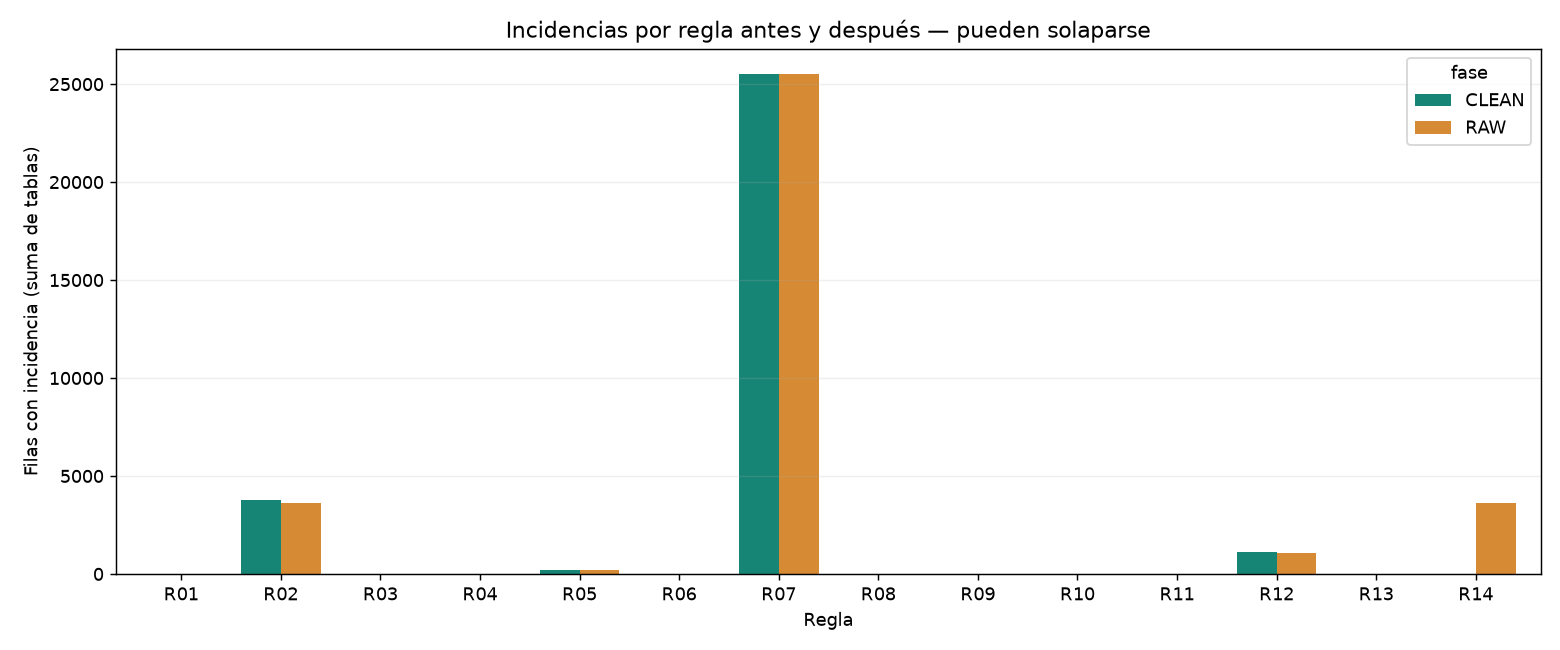

In [12]:
comparison = con.sql("""SELECT substr(nombre_regla,1,3) regla, fase, sum(registros_invalidos) incidencias
    FROM audit.quality_report WHERE fase IN ('RAW','CLEAN') GROUP BY 1,2 ORDER BY 1,2""").df()
chart_data = comparison.pivot(index="regla", columns="fase", values="incidencias")
display(chart_data)
ax = chart_data.plot.bar(figsize=(12, 5), color=["#168575", "#D68A33"], width=0.8)
ax.set_title("Incidencias por regla antes y después — pueden solaparse")
ax.set_ylabel("Filas con incidencia (suma de tablas)")
ax.set_xlabel("Regla")
ax.grid(axis="y", alpha=0.2)
plt.xticks(rotation=0)
plt.tight_layout()
from io import BytesIO
from IPython.display import Image

figure_buffer = BytesIO()
ax.figure.savefig(figure_buffer, format="png", dpi=130)
display(Image(data=figure_buffer.getvalue()))
plt.close(ax.figure)


## 12. Validaciones automatizadas
Este bloque vuelve a consultar CLEAN directamente; no confía en que las transformaciones
hayan funcionado. Verifica estructura, claves, tipos, dominios, relaciones, cronología,
postales, estados, métodos, conciliación, partición de filas, evidencia temporal, cambios
y cobertura de inyecciones. Cualquier FAIL bloquea la exportación.

Las pruebas negativas alteran CLEAN/AUDIT dentro de transacciones que siempre se revierten.
Se exige que el control esperado falle; no basta con que ocurra una excepción cualquiera.
La prueba de conciliación exige WARNING y demuestra que se preservan las diferencias legítimas.


In [13]:
def validations():
    checks = []

    def add(name, n, bad, sql="", warning=False):
        checks.append(
            dict(
                control=name,
                evaluados=int(n),
                invalidos=int(bad),
                estado="WARNING" if bad and warning else "FAIL" if bad else "PASS",
                sql=sql,
            )
        )

    def check(name, sql, n=1, warning=False):
        add(name, n, scalar(sql), sql, warning)

    for schema in ("raw", "clean"):
        names = {
            r[0]
            for r in con.execute(
                "SELECT table_name FROM information_schema.tables WHERE table_schema=? AND table_type='BASE TABLE'",
                [schema],
            ).fetchall()
        }
        add(f"estructura_tablas_{schema}", 5, len(names.symmetric_difference(SCHEMA)))
        for t in SCHEMA:
            expected = [
                (c, "VARCHAR" if schema == "raw" else TYPES[t][c]) for c in SCHEMA[t]
            ]
            add(
                f"estructura_{schema}_{t}",
                len(expected),
                int(t not in names or signature(f"{schema}.{t}") != expected),
            )
    if any(c["estado"] == "FAIL" for c in checks):
        return checks
    for t, cols in SCHEMA.items():
        n = scalar(f"SELECT count(*) FROM clean.{t}")
        check(
            f"obligatorios_{t}",
            f"SELECT count(*) FROM clean.{t} WHERE "
            + " OR ".join(f"{qi(c)} IS NULL" for c in REQUIRED[t]),
            n,
        )
        check(
            f"unicidad_{t}",
            f"SELECT coalesce(sum(n-1),0) FROM (SELECT count(*) n FROM clean.{t} GROUP BY "
            + ", ".join(qi(k) for k in KEYS[t])
            + ")",
            n,
        )
        textcols = [c for c in cols if TYPES[t][c] == "VARCHAR"]
        check(
            f"vacios_{t}",
            f"SELECT count(*) FROM clean.{t} WHERE "
            + " OR ".join(
                f"({qi(c)} IS NOT NULL AND trim({qi(c)})='')" for c in textcols
            ),
            n,
        )
        domain = []
        for c, typ in TYPES[t].items():
            if typ in ("DOUBLE", "INTEGER", "DECIMAL(18,2)"):
                lower = 1 if c in ("order_item_id", "payment_sequential") else 0
                domain.append(
                    f"({qi(c)}<{lower}"
                    + (f" OR NOT isfinite({qi(c)})" if typ == "DOUBLE" else "")
                    + ")"
                )
        if domain:
            check(
                f"dominio_{t}",
                f"SELECT count(*) FROM clean.{t} WHERE " + " OR ".join(domain),
                n,
            )
        raw_n = scalar(f"SELECT count(*) FROM raw.{t}")
        # Partición multiconjunto: ni perder filas ni atribuir la misma fila dos veces.
        expected = f"(SELECT row_number() OVER () fila FROM raw.{t})"
        actual = f"(SELECT fila FROM audit.lineage WHERE tabla={qs(t)} UNION ALL SELECT fila FROM audit.quarantine WHERE tabla={qs(t)})"
        add(
            f"balance_{t}",
            raw_n,
            differences(expected, actual),
            "EXCEPT ALL: rowid RAW frente a linaje UNION ALL cuarentena",
        )
        actual_keys = f"(SELECT clave FROM audit.lineage WHERE tabla={qs(t)})"
        clean_keys = f"(SELECT {key_expr(t)} clave FROM clean.{t})"
        add(
            f"linaje_{t}",
            n,
            differences(actual_keys, clean_keys),
            "EXCEPT ALL: claves CLEAN frente a audit.lineage",
        )
        json_row = (
            "to_json(struct_pack("
            + ", ".join(qi(c) + ":=r." + qi(c) for c in cols)
            + "))"
        )
        check(
            f"evidencia_cuarentena_{t}",
            f"""SELECT count(*) FROM audit.quarantine q LEFT JOIN (SELECT row_number() OVER ()-1 rowid,* FROM raw.{t}) r ON r.rowid+1=q.fila
            WHERE q.tabla={qs(t)} AND (r.rowid IS NULL OR q.fila_original IS DISTINCT FROM CAST({json_row} AS VARCHAR) OR NULLIF(q.motivos,'') IS NULL)""",
            raw_n,
        )
        # RAW se compara contra la copia CSV completa, incluso ceros/vacíos y duplicados.
        add(
            f"fidelidad_raw_{t}",
            raw_n,
            differences(f"raw.{t}", csv_relation(COPIES_DIR / FILES[t], t)),
            "EXCEPT ALL bidireccional RAW/CSV alterado",
        )
        if t in MONEY:
            predicates = " OR ".join(
                f"c.{qi(c)} IS DISTINCT FROM TRY_CAST(r.{qi(c)} AS DECIMAL(18,2))"
                for c in MONEY[t]
            )
            check(
                f"importes_conservados_{t}",
                f"""SELECT count(*) FROM clean.{t} c
                JOIN audit.lineage l ON l.tabla={qs(t)} AND l.clave={key_expr(t, "c")}
                JOIN (SELECT row_number() OVER () fila,* FROM raw.{t}) r ON r.fila=l.fila
                WHERE {predicates}""",
                n,
            )
        dates = [c for c in cols if TYPES[t][c] == "TIMESTAMP"]
        if dates:
            check(
                f"fechas_finitas_{t}",
                f"SELECT count(*) FROM clean.{t} WHERE "
                + " OR ".join(
                    f"({qi(c)} IS NOT NULL AND NOT isfinite({qi(c)}))" for c in dates
                ),
                n,
            )
    for child, col, parent, pcol in RELATIONS:
        check(
            f"fk_{child}_{col}",
            f"SELECT count(*) FROM clean.{child} c WHERE NOT EXISTS (SELECT 1 FROM clean.{parent} p WHERE c.{qi(col)}=p.{qi(pcol)})",
            scalar(f"SELECT count(*) FROM clean.{child}"),
        )
    check(
        "cronologia",
        f"SELECT count(*) FROM clean.orders WHERE {CARRIER_BAD} OR {OTHER_TIME_BAD}",
        scalar("SELECT count(*) FROM clean.orders"),
    )
    check(
        "estados",
        f"SELECT count(*) FROM clean.orders WHERE {STATUS_BAD}",
        scalar("SELECT count(*) FROM clean.orders"),
    )
    check(
        "postales",
        "SELECT count(*) FROM clean.customers WHERE customer_zip_code_prefix IS NOT NULL AND NOT regexp_full_match(customer_zip_code_prefix,'[0-9]{5}')",
        scalar("SELECT count(*) FROM clean.customers"),
    )
    check(
        "metodos",
        f"SELECT count(*) FROM clean.order_payments WHERE payment_type IS NULL OR payment_type NOT IN {METHODS}",
        scalar("SELECT count(*) FROM clean.order_payments"),
    )
    check(
        "conciliacion",
        f"""WITH i AS (SELECT order_id,sum(price+freight_value) v FROM clean.order_items GROUP BY 1),
        p AS (SELECT order_id,sum(payment_value) v FROM clean.order_payments GROUP BY 1)
        SELECT count(*) FROM clean.orders o LEFT JOIN i USING(order_id) LEFT JOIN p USING(order_id)
        WHERE i.v IS NULL OR p.v IS NULL OR abs(i.v-p.v)>{TOLERANCE}""",
        scalar("SELECT count(*) FROM clean.orders"),
        True,
    )
    # Reconstruir expectativa R05 desde RAW y linaje: no fiarse de audit.findings.
    raw_temporal = f"""(SELECT l.fila,r.order_id, TRY_CAST(NULLIF(trim(r.order_delivered_carrier_date),'') AS TIMESTAMP) timestamp_original
        FROM (SELECT row_number() OVER ()-1 rowid,* FROM raw.orders) r JOIN audit.lineage l ON l.tabla='orders' AND l.fila=r.rowid+1
        WHERE TRY_CAST(r.order_delivered_carrier_date AS TIMESTAMP)<TRY_CAST(r.order_purchase_timestamp AS TIMESTAMP)
           OR TRY_CAST(r.order_delivered_customer_date AS TIMESTAMP)<TRY_CAST(r.order_delivered_carrier_date AS TIMESTAMP))"""
    add(
        "evidencia_temporal",
        scalar("SELECT count(*) FROM clean.orders"),
        differences(
            raw_temporal,
            "(SELECT fila,order_id,timestamp_original FROM audit.temporal_events)",
        ),
        "EXCEPT ALL: eventos RAW y eventos auditados",
    )
    check(
        "aplicacion_temporal",
        f"""SELECT count(*) FROM clean.orders c JOIN audit.lineage l ON l.tabla='orders' AND l.clave={key_expr("orders", "c")}
        JOIN (SELECT row_number() OVER ()-1 rowid,* FROM raw.orders) r ON r.rowid+1=l.fila LEFT JOIN audit.temporal_events e ON e.fila=l.fila
        WHERE c.order_delivered_carrier_date IS DISTINCT FROM
          CASE WHEN e.fila IS NOT NULL THEN NULL ELSE TRY_CAST(NULLIF(trim(r.order_delivered_carrier_date),'') AS TIMESTAMP) END""",
    )
    expected_changes = []
    for t, cols in SCHEMA.items():
        for c in cols:
            rule = (
                "R05"
                if c == "order_delivered_carrier_date"
                else "R11"
                if c == "customer_zip_code_prefix"
                else "R08"
                if c == "product_category_name"
                else "R13"
                if c == "payment_type"
                else "R04"
                if TYPES[t][c] != "VARCHAR"
                else "R03"
            )
            expected_changes.append(f"""SELECT CASE WHEN trim(r.{qi(c)})='' THEN 'R14' ELSE {qs(rule)} END regla,
              {qs(t)} tabla,l.fila,{qs(c)} campo,r.{qi(c)} antes,CAST(c.{qi(c)} AS VARCHAR) despues
              FROM clean.{t} c JOIN audit.lineage l ON l.tabla={qs(t)} AND l.clave={key_expr(t, "c")}
              JOIN (SELECT row_number() OVER ()-1 rowid,* FROM raw.{t}) r ON r.rowid+1=l.fila WHERE r.{qi(c)} IS DISTINCT FROM CAST(c.{qi(c)} AS VARCHAR)""")
    add(
        "evidencia_cambios",
        scalar("SELECT count(*) FROM audit.changes"),
        differences("(" + " UNION ALL ".join(expected_changes) + ")", "audit.changes"),
        "EXCEPT ALL: cambios reales y bitácora",
    )
    check(
        "cobertura_inyecciones",
        "SELECT count(*) FROM audit.injection_coverage WHERE NOT detectada",
        len(INJECTIONS),
    )
    check(
        "cobertura_catalogo",
        f"SELECT abs(count(*)-{len(INJECTIONS)}) FROM audit.injection_coverage",
        len(INJECTIONS),
    )
    check(
        "fallos_clean_no_gestionados",
        "SELECT count(*) FROM audit.findings WHERE fase='CLEAN' AND severidad IN ('CRITICAL','TREATABLE')",
    )
    check(
        "porcentajes",
        "SELECT count(*) FROM audit.quality_report WHERE registros_invalidos>registros_evaluados OR (registros_evaluados=0 AND porcentaje_error IS NOT NULL) OR (registros_evaluados>0 AND abs(porcentaje_error-100.0*registros_invalidos/registros_evaluados)>0.0000001)",
    )
    add(
        "originales_intactos",
        5,
        sum(sha256(INPUT_DIR / r["archivo"]) != r["sha256"] for r in ORIGINALS),
        "SHA-256 original antes/después",
    )
    return checks


NEGATIVE_CASES = [
    (
        "duplicado",
        "unicidad_customers",
        "INSERT INTO clean.customers SELECT * FROM clean.customers LIMIT 1",
    ),
    (
        "obligatorio",
        "obligatorios_customers",
        "UPDATE clean.customers SET customer_unique_id=NULL WHERE rowid=(SELECT min(rowid) FROM clean.customers)",
    ),
    (
        "importe",
        "dominio_order_items",
        "UPDATE clean.order_items SET price=-1 WHERE rowid=(SELECT min(rowid) FROM clean.order_items)",
    ),
    (
        "importe_no_autorizado",
        "importes_conservados_order_items",
        "UPDATE clean.order_items SET price=price+1 WHERE rowid=(SELECT min(rowid) FROM clean.order_items)",
    ),
    (
        "relacion",
        "fk_orders_customer_id",
        "UPDATE clean.orders SET customer_id='inexistente_r15' WHERE rowid=(SELECT min(rowid) FROM clean.orders)",
    ),
    (
        "fecha",
        "cronologia",
        "UPDATE clean.orders SET order_approved_at=order_purchase_timestamp-INTERVAL 1 DAY WHERE rowid=(SELECT min(rowid) FROM clean.orders)",
    ),
    (
        "fecha_no_finita",
        "fechas_finitas_orders",
        "UPDATE clean.orders SET order_estimated_delivery_date=TIMESTAMP 'infinity' WHERE rowid=(SELECT min(rowid) FROM clean.orders)",
    ),
    (
        "postal",
        "postales",
        "UPDATE clean.customers SET customer_zip_code_prefix='XYZ' WHERE rowid=(SELECT min(rowid) FROM clean.customers)",
    ),
    (
        "metodo",
        "metodos",
        "UPDATE clean.order_payments SET payment_type='desconocido_r15' WHERE rowid=(SELECT min(rowid) FROM clean.order_payments)",
    ),
    (
        "estado",
        "estados",
        "UPDATE clean.orders SET order_status='desconocido_r15' WHERE rowid=(SELECT min(rowid) FROM clean.orders)",
    ),
    ("evidencia_r05", "evidencia_temporal", "DELETE FROM audit.temporal_events"),
    (
        "balance",
        "balance_customers",
        "DELETE FROM audit.lineage WHERE tabla='customers' AND fila=(SELECT min(fila) FROM audit.lineage WHERE tabla='customers')",
    ),
    ("bitacora", "evidencia_cambios", "DELETE FROM audit.changes"),
    (
        "esquema",
        "estructura_clean_products",
        "ALTER TABLE clean.products ADD COLUMN columna_indebida VARCHAR",
    ),
    (
        "diferencia_pago",
        "conciliacion",
        "UPDATE clean.order_payments SET payment_value=payment_value+999999 WHERE rowid=(SELECT min(rowid) FROM clean.order_payments)",
    ),
]


def negative_tests():
    baseline = {r["control"]: r["invalidos"] for r in validations()}
    for name, expected, mutation in NEGATIVE_CASES:
        con.execute("BEGIN TRANSACTION")
        try:
            con.execute(mutation)
            results = validations()
            detected = any(
                r["control"] == expected
                and r["invalidos"] > baseline[expected]
                and r["estado"] == ("WARNING" if expected == "conciliacion" else "FAIL")
                for r in results
            )
        finally:
            con.execute("ROLLBACK")
        if not detected:
            raise AssertionError(f"R15 no detectó {name}: {expected}")
        con.execute(
            "INSERT INTO audit.negative_tests VALUES (?,?,?)",
            [name, expected, detected],
        )


def finish_run():
    try:
        checks = validations()
        con.executemany(
            "INSERT INTO audit.checks VALUES (?,?,?,?,?)",
            [list(r.values()) for r in checks],
        )
        if any(r["estado"] == "FAIL" for r in checks):
            raise AssertionError(
                "Publicación bloqueada: "
                + str([r for r in checks if r["estado"] == "FAIL"])
            )
        con.execute("COMMIT")
    except Exception:
        con.execute("ROLLBACK")
        con.close()
        raise
    negative_tests()
    checks = validations()
    assert all(r["estado"] != "FAIL" for r in checks), (
        "La restauración de las pruebas negativas falló."
    )
    con.execute(
        "INSERT INTO audit.checks VALUES ('pruebas_negativas',?,?, 'PASS','Transacciones revertidas')",
        [len(NEGATIVE_CASES), 0],
    )
    # R15 RAW: unidades = consultas críticas del diagnóstico, fallidas si tienen hallazgos.
    evaluated, invalid = con.execute("""SELECT count(*), count(*) FILTER(WHERE EXISTS (
        SELECT 1 FROM audit.findings f WHERE f.fase=q.fase AND f.regla=q.regla AND f.tabla=q.tabla AND f.detalle=q.detalle))
        FROM audit.queries q WHERE fase='RAW' AND severidad IN ('CRITICAL','TREATABLE')""").fetchone()
    con.execute(
        "INSERT INTO audit.quality_report VALUES (?,?,?,?,?,?,?,?,?,?)",
        [
            "R15 Control final",
            "pipeline",
            evaluated,
            invalid,
            100 * invalid / evaluated if evaluated else None,
            RUN_TIME,
            RUN_ID,
            "RAW",
            "FAIL" if invalid else "PASS",
            True,
        ],
    )
    n = scalar("SELECT count(*) FROM audit.checks")
    con.execute(
        "INSERT INTO audit.quality_report VALUES (?,?,?,?,?,?,?,?,?,?)",
        [
            "R15 Control final",
            "pipeline",
            n,
            0,
            0.0,
            RUN_TIME,
            RUN_ID,
            "CLEAN",
            "PASS",
            True,
        ],
    )
    con.execute(
        "INSERT INTO audit.rule_results VALUES (?,?,?,?,?,?,?,?)",
        ["R15", "pipeline", evaluated, invalid, 0, 0, 0, 0],
    )
    return checks


CHECKS = finish_run()
display(con.sql("SELECT * EXCLUDE(sql) FROM audit.checks ORDER BY control").df())
display(con.sql("SELECT * FROM audit.negative_tests").df())
display(
    con.sql("""SELECT regla,sum(evaluados) evaluados,sum(detectados) detectados,sum(corregidos) corregidos,
    sum(cuarentena) cuarentena,sum(pendientes) pendientes,sum(posteriores) posteriores
    FROM audit.rule_results GROUP BY 1 ORDER BY 1""").df()
)
print(
    "Control final: PASS; advertencias documentadas:",
    sum(r["estado"] == "WARNING" for r in CHECKS),
)


,control,evaluados,invalidos,estado
0,aplicacion_temporal,1,0,PASS
1,balance_customers,99443,0,PASS
2,balance_order_items,112652,0,PASS
3,balance_order_payments,103888,0,PASS
4,balance_orders,99443,0,PASS
...,...,...,...,...
67,vacios_customers,99438,0,PASS
68,vacios_order_items,112623,0,PASS
69,vacios_order_payments,103863,0,PASS
70,vacios_orders,99424,0,PASS


,prueba,control_esperado,detectado
0,duplicado,unicidad_customers,True
1,obligatorio,obligatorios_customers,True
2,importe,dominio_order_items,True
3,importe_no_autorizado,importes_conservados_order_items,True
4,relacion,fk_orders_customer_id,True
5,fecha,cronologia,True
6,fecha_no_finita,fechas_finitas_orders,True
7,postal,postales,True
8,metodo,metodos,True
9,estado,estados,True


,regla,evaluados,detectados,corregidos,cuarentena,pendientes,posteriores
0,R01,448379.0,20.0,5.0,15.0,0.0,0.0
1,R02,448379.0,3597.0,0.0,11.0,3586.0,3775.0
2,R03,198886.0,2.0,2.0,0.0,0.0,0.0
3,R04,448379.0,7.0,0.0,7.0,0.0,0.0
4,R05,99443.0,191.0,190.0,1.0,190.0,190.0
5,R06,216540.0,4.0,0.0,4.0,0.0,0.0
6,R07,216540.0,25540.0,0.0,5.0,25535.0,25535.0
7,R08,32953.0,1.0,1.0,0.0,0.0,0.0
8,R09,315983.0,4.0,0.0,44.0,0.0,0.0
9,R10,99443.0,11.0,0.0,11.0,0.0,0.0


Control final: PASS; advertencias documentadas: 1


## 13. Demostración de idempotencia
Se ejecuta otra vez el pipeline completo: regeneración de copias, RAW, diagnóstico,
transformación, auditoría, controles y pruebas negativas. Se comparan **todas las filas con
EXCEPT ALL en ambos sentidos**, esquemas y conteos de RAW, CLEAN y todas las tablas AUDIT.
También se comparan hashes de originales/copias y el contenido lógico de dos exportaciones.
Los archivos candidatos se escriben aquí para incluir Parquet en la prueba; sólo se publican
en la siguiente sección. El identificador incluye fuentes, política, semilla, tolerancia y versiones.

Los cronómetros no forman parte de tablas persistentes. Las auditorías del snapshot actual
se reconstruyen transaccionalmente; `audit.runs` conserva una fila por ejecución lógica.


In [14]:
def verify_parquets(folder):
    verified = []
    if {p.name for p in folder.glob("*.parquet")} != {f"{t}.parquet" for t in SCHEMA}:
        raise AssertionError("La publicación no contiene exactamente cinco Parquet.")
    for t in SCHEMA:
        path = folder / f"{t}.parquet"
        relation = f"read_parquet({qs(path.resolve().as_posix())})"
        if signature(relation) != signature(f"clean.{t}"):
            raise AssertionError(f"Esquema Parquet: {t}")
        diff = differences(f"clean.{t}", relation)
        if diff:
            raise AssertionError(f"Contenido Parquet: {t}, {diff} diferencias")
        verified.append(
            dict(
                tabla=t,
                archivo=path.name,
                registros=scalar(f"SELECT count(*) FROM {relation}"),
                columnas_tipos=signature(relation),
                bytes=path.stat().st_size,
                sha256=sha256(path),
                diferencias=diff,
            )
        )
    return verified


def export_candidate():
    checks = validations()
    if any(r["estado"] == "FAIL" for r in checks):
        raise AssertionError("Exportación bloqueada por controles críticos.")
    folder = Path(tempfile.mkdtemp(prefix=".parquet-candidato-", dir=OUTPUT_DIR))
    try:
        for t in SCHEMA:
            columns = ", ".join(qi(c) for c in KEYS[t])
            con.execute(
                f"COPY (SELECT * FROM clean.{t} ORDER BY {columns}) TO {qs((folder / (t + '.parquet')).resolve().as_posix())} (FORMAT PARQUET, COMPRESSION ZSTD)"
            )
        verified = verify_parquets(folder)
        manifest = dict(
            run_id=RUN_ID,
            fecha_ejecucion=RUN_TIME.isoformat() + "Z",
            config=CONFIG,
            compresion="ZSTD",
            estado="VERIFICADO",
            archivos=verified,
        )
        (folder / "manifest.json").write_text(
            json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        return folder
    except Exception:
        safe_remove_candidate(folder)
        raise


def safe_remove_candidate(folder):
    # Sólo directorios temporales creados por este notebook dentro de OUTPUT_DIR.
    resolved = Path(folder).resolve()
    if resolved.parent != OUTPUT_DIR.resolve() or not resolved.name.startswith(
        ".parquet-candidato-"
    ):
        raise ValueError(f"No se permite borrar esta ruta: {resolved}")
    shutil.rmtree(resolved)


def repeat_pipeline():
    current = inventory()
    if current != ORIGINALS:
        raise AssertionError("Los originales cambiaron entre ejecuciones.")
    injections = generate_copies()
    if injections != INJECTIONS:
        raise AssertionError("Inyecciones no deterministas.")
    try:
        start_run(injections)
        run_diagnostics()
        build_clean()
        clean_diagnostics()
        reports()
    except Exception:
        con.execute("ROLLBACK")
        con.close()
        raise
    return finish_run()


SNAPSHOTS = {}
for schema in ("raw", "clean", "audit"):
    tables = con.execute(
        "SELECT table_name FROM information_schema.tables WHERE table_schema=? AND table_type='BASE TABLE' ORDER BY table_name",
        [schema],
    ).fetchall()
    for (t,) in tables:
        source = f"{schema}.{t}"
        snapshot = f"snapshot_{schema}_{t}"
        con.execute(
            f"CREATE OR REPLACE TEMP TABLE {snapshot} AS SELECT * FROM {source}"
        )
        SNAPSHOTS[source] = (
            snapshot,
            signature(source),
            scalar(f"SELECT count(*) FROM {source}"),
        )
COPY_HASHES = {name: sha256(COPIES_DIR / name) for name in FILES.values()}
ROUND_ONE = export_candidate()
CHECKS = (
    repeat_pipeline()
)  # Segunda ejecución REAL, no un reuso del resultado anterior.
ROUND_TWO = export_candidate()
IDEMPOTENCE = []
for relation, (snapshot, expected_schema, expected_count) in SNAPSHOTS.items():
    row = dict(
        objeto=relation,
        esquema=signature(relation) == expected_schema,
        conteo=scalar(f"SELECT count(*) FROM {relation}") == expected_count,
        diferencias=differences(relation, snapshot),
    )
    IDEMPOTENCE.append(row)
    if not row["esquema"] or not row["conteo"] or row["diferencias"]:
        raise AssertionError(f"Idempotencia fallida: {row}")
for t in SCHEMA:
    first = f"read_parquet({qs((ROUND_ONE / (t + '.parquet')).resolve().as_posix())})"
    second = f"read_parquet({qs((ROUND_TWO / (t + '.parquet')).resolve().as_posix())})"
    assert signature(first) == signature(second), f"Esquema Parquet no idempotente: {t}"
    assert differences(first, second) == 0, f"Contenido Parquet no idempotente: {t}"
assert COPY_HASHES == {name: sha256(COPIES_DIR / name) for name in FILES.values()}, (
    "Copias cambiaron"
)
assert ORIGINALS == inventory(), "Originales cambiaron"
IDEMPOTENCE_PASSED = True
safe_remove_candidate(ROUND_ONE)
display(pd.DataFrame(IDEMPOTENCE))
print(
    "IDEMPOTENCIA: PASS — tablas, auditorías, copias, originales y cinco Parquet verificados"
)


,objeto,esquema,conteo,diferencias
0,raw.customers,True,True,0
1,raw.order_items,True,True,0
2,raw.order_payments,True,True,0
3,raw.orders,True,True,0
4,raw.products,True,True,0
5,clean.customers,True,True,0
6,clean.order_items,True,True,0
7,clean.order_payments,True,True,0
8,clean.orders,True,True,0
9,clean.products,True,True,0


IDEMPOTENCIA: PASS — tablas, auditorías, copias, originales y cinco Parquet verificados


## 14. Exportación Parquet
Los cinco Parquet ZSTD y su manifiesto se publican juntos mediante el renombrado de una
carpeta candidata ya verificada, dentro del mismo filesystem. Una carpeta incompleta nunca
se presenta como publicación. La ruta final usa el identificador lógico; una reejecución
idéntica verifica y reutiliza esa publicación, sin acumular archivos.

DuckDB y filesystem no constituyen una transacción distribuida: ante una interrupción, un lote previo
puede seguir en disco; el consumidor debe comprobar run_id y manifiesto. Reejecutar recupera
el proceso. Los directorios candidatos no son entregables publicados.


In [15]:
assert IDEMPOTENCE_PASSED
release_root = OUTPUT_DIR / "publicaciones"
release_root.mkdir(exist_ok=True)
RELEASE_DIR = release_root / RUN_ID
if RELEASE_DIR.exists():
    existing = json.loads((RELEASE_DIR / "manifest.json").read_text(encoding="utf-8"))
    assert existing["run_id"] == RUN_ID
    verify_parquets(RELEASE_DIR)
    for entry in existing["archivos"]:
        assert sha256(RELEASE_DIR / entry["archivo"]) == entry["sha256"], (
            "Hash del release existente no coincide"
        )
    safe_remove_candidate(ROUND_TWO)
else:
    ROUND_TWO.rename(RELEASE_DIR)
pointer = {
    "run_id": RUN_ID,
    "carpeta": str(RELEASE_DIR.relative_to(OUTPUT_DIR)),
    "manifest": "manifest.json",
}
pointer_tmp = OUTPUT_DIR / "publicacion_actual.json.tmp"
pointer_tmp.write_text(json.dumps(pointer, indent=2), encoding="utf-8")
os.replace(pointer_tmp, OUTPUT_DIR / "publicacion_actual.json")
display(pd.DataFrame(verify_parquets(RELEASE_DIR)))


,tabla,archivo,registros,columnas_tipos,bytes,sha256,diferencias
0,customers,customers.parquet,99438,"[(customer_id, VARCHAR), (customer_unique_id, ...",4030141,f66818260c7ba53e8b55d0d1872b12ec6a24d5ec5ce446...,0
1,orders,orders.parquet,99424,"[(order_id, VARCHAR), (customer_id, VARCHAR), ...",6122463,e12ea774051e60eb9fb1f8af1a47b2379ec6ccfe936296...,0
2,order_items,order_items.parquet,112623,"[(order_id, VARCHAR), (order_item_id, INTEGER)...",3995698,e5f63c7a667e4f5cb4da97db0b69cfcadc9d4ecd67fcb0...,0
3,order_payments,order_payments.parquet,103863,"[(order_id, VARCHAR), (payment_sequential, INT...",2094065,c7d39649587e66e2df9636fe4f41e35d441c6acd7529fc...,0
4,products,products.parquet,32948,"[(product_id, VARCHAR), (product_category_name...",841699,f66392330165472b27fe33858bc27b10989587abb70b24...,0


## 15. Verificación final
Se releen los archivos publicados, se repiten conteos, esquemas e igualdad multiconjunto,
se comprueban los hashes del manifiesto y de los cinco originales y se cierra DuckDB.
Después se abre en modo sólo lectura para demostrar que los objetos son persistentes.


In [16]:
PARQUETS = verify_parquets(RELEASE_DIR)
manifest = json.loads((RELEASE_DIR / "manifest.json").read_text(encoding="utf-8"))
assert manifest["run_id"] == RUN_ID
for entry in manifest["archivos"]:
    assert sha256(RELEASE_DIR / entry["archivo"]) == entry["sha256"]
    assert (RELEASE_DIR / entry["archivo"]).stat().st_size == entry["bytes"]
assert ORIGINALS == inventory()
FINAL_CHECKS = validations()
assert all(r["estado"] != "FAIL" for r in FINAL_CHECKS)
SUMMARY = table_summary()
RULE_RESULTS = con.sql("""SELECT regla,sum(evaluados) evaluados,sum(detectados) detectados,sum(corregidos) corregidos,
    sum(cuarentena) cuarentena,sum(pendientes) pendientes,sum(posteriores) posteriores
    FROM audit.rule_results GROUP BY 1 ORDER BY 1""").df()
QUALITY = con.sql(
    "SELECT * FROM audit.quality_report ORDER BY fase,nombre_regla,tabla_evaluada"
).df()
COUNTS = {t: scalar(f"SELECT count(*) FROM audit.{t}") for t in AUDIT_DDL}
TEMPORAL_SUMMARY = con.sql(
    "SELECT origen,count(*) eventos FROM audit.temporal_events GROUP BY 1 ORDER BY 1"
).df()
QUALITY.to_csv(OUTPUT_DIR / "quality_report.csv", index=False)
SUMMARY.to_csv(OUTPUT_DIR / "resumen_tablas.csv", index=False)
RULE_RESULTS.to_csv(OUTPUT_DIR / "resumen_reglas.csv", index=False)
con.execute("CHECKPOINT")
con.close()
with duckdb.connect(str(DB_PATH), read_only=True) as persisted:
    assert (
        persisted.execute("SELECT count(*) FROM audit.quality_report").fetchone()[0]
        == COUNTS["quality_report"]
    )
    for r in SUMMARY.to_dict("records"):
        assert (
            persisted.execute(f"SELECT count(*) FROM clean.{r['tabla']}").fetchone()[0]
            == r["limpios"]
        )
print("Verificación persistente: PASS. Conexiones cerradas.")


Verificación persistente: PASS. Conexiones cerradas.


## 16. Resultados y conclusiones
Las cifras siguientes proceden de las ejecuciones reales, incluidos los errores artificiales.
La reducción de incidencias combina normalizaciones, cuarentenas y el tratamiento R05;
no demuestra haber recuperado todos los valores verdaderos. Las advertencias de completitud,
IQR y conciliación necesitan investigación; la fecha suprimida sigue sin verificarse.


In [17]:
RESULT = {
    "run_id": RUN_ID,
    "fecha_ejecucion_utc": RUN_TIME.isoformat() + "Z",
    "versiones": VERSIONS,
    "idempotencia": "PASS",
    "ejecuciones_pipeline": 2,
    "transformaciones_SQL_porcentaje": SQL_PERCENT,
    "controles": COUNTS["checks"],
    "pruebas_negativas": COUNTS["negative_tests"],
    "inyecciones": COUNTS["injections"],
    "inyecciones_detectadas": COUNTS["injection_coverage"],
    "quality_report_filas": COUNTS["quality_report"],
    "parquets_verificados": len(PARQUETS),
    "originales_intactos": True,
    "tablas": SUMMARY.to_dict("records"),
    "reglas": RULE_RESULTS.to_dict("records"),
    "eventos_temporales": TEMPORAL_SUMMARY.to_dict("records"),
    "advertencias_controles": [
        r["control"] for r in FINAL_CHECKS if r["estado"] == "WARNING"
    ],
    "base_datos": str(DB_PATH),
    "publicacion": str(RELEASE_DIR),
    "comparaciones_idempotencia": IDEMPOTENCE,
}
(OUTPUT_DIR / "resultado_verificado.json").write_text(
    json.dumps(RESULT, ensure_ascii=False, indent=2), encoding="utf-8"
)
display(SUMMARY)
display(RULE_RESULTS)
display(TEMPORAL_SUMMARY)
display(
    Markdown(
        f"**IDEMPOTENCIA: PASS.** {RESULT['controles']} controles, "
        f"{RESULT['pruebas_negativas']} pruebas negativas, {RESULT['inyecciones']} inyecciones detectadas, "
        f"{len(PARQUETS)} Parquet verificados. Transformaciones SQL: **{SQL_PERCENT:.0f}%**."
    )
)


,tabla,originales,alterados,limpios,cuarentena
0,customers,99441,99443,99438,5
1,orders,99441,99443,99424,19
2,order_items,112650,112652,112623,29
3,order_payments,103886,103888,103863,25
4,products,32951,32953,32948,5


,regla,evaluados,detectados,corregidos,cuarentena,pendientes,posteriores
0,R01,448379.0,20.0,5.0,15.0,0.0,0.0
1,R02,448379.0,3597.0,0.0,11.0,3586.0,3775.0
2,R03,198886.0,2.0,2.0,0.0,0.0,0.0
3,R04,448379.0,7.0,0.0,7.0,0.0,0.0
4,R05,99443.0,191.0,190.0,1.0,190.0,190.0
5,R06,216540.0,4.0,0.0,4.0,0.0,0.0
6,R07,216540.0,25540.0,0.0,5.0,25535.0,25535.0
7,R08,32953.0,1.0,1.0,0.0,0.0,0.0
8,R09,315983.0,4.0,0.0,44.0,0.0,0.0
9,R10,99443.0,11.0,0.0,11.0,0.0,0.0


,origen,eventos
0,inyeccion_directa,1
1,preexistente,189


**IDEMPOTENCIA: PASS.** 72 controles, 15 pruebas negativas, 41 inyecciones detectadas, 5 Parquet verificados. Transformaciones SQL: **100%**.

## 17. Entregables
La base se puede abrir independientemente con DuckDB y `SELECT * FROM audit.quality_report`. Los resultados generados se almacenan
en la carpeta configurada, junto al catálogo, el resumen y el puntero al manifiesto vigente.


In [18]:
deliverables = [
    DB_PATH,
    OUTPUT_DIR / "inyecciones.json",
    OUTPUT_DIR / "quality_report.csv",
    OUTPUT_DIR / "resumen_tablas.csv",
    OUTPUT_DIR / "resumen_reglas.csv",
    OUTPUT_DIR / "resultado_verificado.json",
    OUTPUT_DIR / "publicacion_actual.json",
    RELEASE_DIR / "manifest.json",
]
deliverables += [RELEASE_DIR / f"{t}.parquet" for t in SCHEMA]
assert all(p.is_file() for p in deliverables)
display(
    pd.DataFrame(
        [
            dict(archivo=str(p), bytes=p.stat().st_size, existe=p.is_file())
            for p in deliverables
        ]
    )
)
print("Entregables completos y verificados. Originales intactos.")


,archivo,bytes,existe
0,resultados_simplificado\olist_data_quality.duckdb,109850624,True
1,resultados_simplificado\inyecciones.json,22455,True
2,resultados_simplificado\quality_report.csv,31720,True
3,resultados_simplificado\resumen_tablas.csv,214,True
4,resultados_simplificado\resumen_reglas.csv,627,True
5,resultados_simplificado\resultado_verificado.json,7773,True
6,resultados_simplificado\publicacion_actual.json,213,True
7,resultados_simplificado\publicaciones\9a1da5be...,4988,True
8,resultados_simplificado\publicaciones\9a1da5be...,4030141,True
9,resultados_simplificado\publicaciones\9a1da5be...,6122463,True


Entregables completos y verificados. Originales intactos.
